<h1>Marvel comics data analysis</h1>

<p>We will construct a graph from the processed data and observe intereting properties about it</p>

In [2]:
import csv


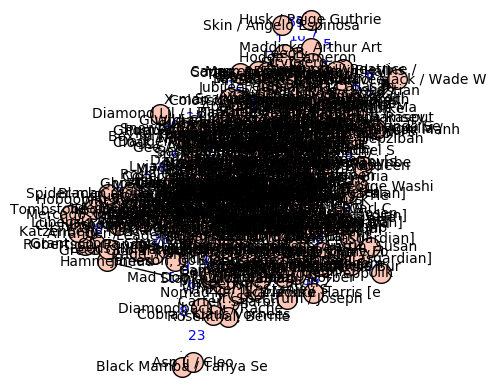

In [16]:
G=Graph(weighted=True)
csv_path='../data/processed/marvel/marvel_edges_clean.csv'

nodes=set()
edges=set()


with open(csv_path,mode='r') as f:
    lines=csv.reader(f)
    next(lines) #Skip headers
    for l in lines:
        source:str=l[0]
        target:str=l[1]
        weight:int=int(l[2])
        
        nodes.add(source)
        nodes.add(target)
        edges.add((source,target,weight))
        

G.add_vertices(nodes)
G.add_edges(edges)

        
G.plot(edge_labels=True)

            
            
    


<h1>Study of properties</h1>

<h4>Character who has the most number of interactions </h2>

In [18]:
def number_of_interactions(character:str)->int:
    res=0
    for e in G.edges():
        if character==e[0] or character==e[1]: #Character is source or target
            res+=e[2]
    return res
    


max_interactions_node=max(G.vertices(),key=number_of_interactions)

show(max_interactions_node)

'Captain America'

<h4>Communities</h4>


In [32]:

from networkx.algorithms import community as nxc

H = G.networkx_graph(weight_function=lambda e:e[2])

comms = list(nxc.greedy_modularity_communities(H))
show(len(comms))
show(G.density().n(2))

1

0.19

In [34]:
import numpy as np
import networkx as nx
pesos = [d["weight"] for _, _, d in H.edges(data=True)]
print(np.percentile(pesos, [25, 50, 75, 90, 95]))




umbral = np.percentile(pesos, 75)
H2 = nx.Graph()
H2.add_weighted_edges_from(
    (u, v, d["weight"]) for u, v, d in H.edges(data=True) if d["weight"] >= umbral
)
comms = list(nxc.greedy_modularity_communities(H2, weight="weight"))
print(len(comms), nxc.modularity(H2, comms, weight="weight"))
print(sorted(len(c) for c in comms))

[ 7.  11.  21.  45.  74.5]
167 0.04877172607450473
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 5, 5, 5, 5, 6, 6, 6, 7, 9]


NameError: name 'nx' is not defined